In [1]:
import pandas as pd
df=pd.read_csv(r"C:\Users\Asus\Downloads\UPI_Daily_Statistics_june_2021_to_June_2026.csv")
df.head()

,Date,Month,Year,Volume_Million,Value_Crore,Month Name,Quarter,Day,Week,Weekday,Day Number,Day Type,Financial Year
0,2021-06-01,6,2021,97.807,21837.51,June,2,1,22,Tuesday,1,Weekday,2021-2022
1,2021-06-02,6,2021,98.137,20668.35,June,2,2,22,Wednesday,2,Weekday,2021-2022
2,2021-06-03,6,2021,92.800,19629.84,June,2,3,22,Thursday,3,Weekday,2021-2022
3,2021-06-04,6,2021,90.824,18987.07,June,2,4,22,Friday,4,Weekday,2021-2022
4,2021-06-05,6,2021,92.120,18465.68,June,2,5,22,Saturday,5,Weekend,2021-2022


In [2]:
df.drop(columns=["Month","Year","Month Name","Volume_Million"],inplace=True)

In [3]:
df.isna().sum()

Date              0
Value_Crore       0
Quarter           0
Day               0
Week              0
Weekday           0
Day Number        0
Day Type          0
Financial Year    0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.shape

(1856, 9)

In [6]:
df

,Date,Value_Crore,Quarter,Day,Week,Weekday,Day Number,Day Type,Financial Year
0,2021-06-01,21837.51,2,1,22,Tuesday,1,Weekday,2021-2022
1,2021-06-02,20668.35,2,2,22,Wednesday,2,Weekday,2021-2022
2,2021-06-03,19629.84,2,3,22,Thursday,3,Weekday,2021-2022
3,2021-06-04,18987.07,2,4,22,Friday,4,Weekday,2021-2022
4,2021-06-05,18465.68,2,5,22,Saturday,5,Weekend,2021-2022
...,...,...,...,...,...,...,...,...,...
1851,2026-06-26,78222.50,2,26,26,Friday,4,Weekday,2026-2027
1852,2026-06-27,79907.00,2,27,26,Saturday,5,Weekend,2026-2027
1853,2026-06-28,67383.64,2,28,26,Sunday,6,Weekend,2026-2027
1854,2026-06-29,95436.83,2,29,27,Monday,0,Weekday,2026-2027


In [7]:
df.sum(numeric_only=True)

Value_Crore    1.075954e+08
Quarter        4.641000e+03
Day            2.918400e+04
Week           4.910200e+04
Day Number     5.566000e+03
dtype: float64

In [8]:
df.dtypes

Date               object
Value_Crore       float64
Quarter             int64
Day                 int64
Week                int64
Weekday            object
Day Number          int64
Day Type           object
Financial Year     object
dtype: object

In [9]:
category=df.select_dtypes(include="O")

In [10]:
numeric=df.select_dtypes(include='number')

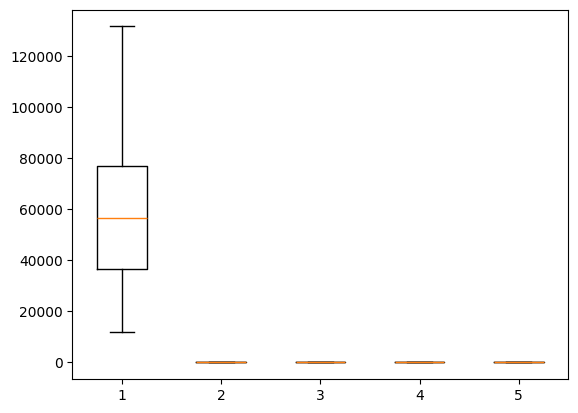

In [11]:
import matplotlib.pyplot as plt
plt.boxplot(numeric)
plt.show()

In [12]:
from sklearn.preprocessing import OrdinalEncoder
oe=OrdinalEncoder()
for i in df:
    df[i]=oe.fit_transform(df[[i]])

In [13]:
df

,Date,Value_Crore,Quarter,Day,Week,Weekday,Day Number,Day Type,Financial Year
0,0.0,108.0,1.0,0.0,21.0,5.0,1.0,0.0,0.0
1,1.0,81.0,1.0,1.0,21.0,6.0,2.0,0.0,0.0
2,2.0,63.0,1.0,2.0,21.0,4.0,3.0,0.0,0.0
3,3.0,46.0,1.0,3.0,21.0,0.0,4.0,0.0,0.0
4,4.0,40.0,1.0,4.0,21.0,2.0,5.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
1851,1851.0,1414.0,1.0,25.0,25.0,0.0,4.0,0.0,5.0
1852,1852.0,1445.0,1.0,26.0,25.0,2.0,5.0,1.0,5.0
1853,1853.0,1153.0,1.0,27.0,25.0,3.0,6.0,1.0,5.0
1854,1854.0,1697.0,1.0,28.0,26.0,1.0,0.0,0.0,5.0


In [14]:
x=df.drop(columns="Value_Crore")
y=df["Value_Crore"]

In [15]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42)

In [17]:
x_train.dtypes

Date              float64
Quarter           float64
Day               float64
Week              float64
Weekday           float64
Day Number        float64
Day Type          float64
Financial Year    float64
dtype: object

In [18]:
y_train.dtypes

dtype('float64')

In [ ]:
# Linear Regression
from sklearn.linear_model import LinearRegression
lr_model=LinearRegression()

In [ ]:
lr_model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
lr_y_pred=lr_model.predict(x_test)

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [ ]:
print("mae:",mean_absolute_error(y_test,lr_y_pred))
print("mse:",mean_squared_error(y_test,lr_y_pred))
print("rmse:",root_mean_squared_error(y_test,lr_y_pred))
print("r2_score:",r2_score(y_test,lr_y_pred))


mae: 92.43188348065067
mse: 16214.531149709552
rmse: 127.33629156571803
r2_score: 0.9442063361959274


In [ ]:
# Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
rfr_model=RandomForestRegressor()

In [ ]:
rfr_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
rfr_y_pred=rfr_model.predict(x_test)

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [ ]:
print("mae:",mean_absolute_error(y_test,rfr_y_pred))
print("mse:",mean_squared_error(y_test,rfr_y_pred))
print("rmse:",root_mean_squared_error(y_test,rfr_y_pred))
print("r2_score:",r2_score(y_test,rfr_y_pred))


mae: 48.12212365591398
mse: 5082.634067473118
rmse: 71.29259475901489
r2_score: 0.9825108247792412


In [ ]:
# Decision Tree Regression
from sklearn.tree import DecisionTreeRegressor
dtr_model=DecisionTreeRegressor()

In [ ]:
dtr_model.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [ ]:
dtr_y_pred=dtr_model.predict(x_test)

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [ ]:
print("mae:",mean_absolute_error(y_test,dtr_y_pred))
print("mse:",mean_squared_error(y_test,dtr_y_pred))
print("rmse:",root_mean_squared_error(y_test,dtr_y_pred))
print("r2_score:",r2_score(y_test,dtr_y_pred))


mae: 69.1236559139785
mse: 10674.344086021505
rmse: 103.31671735988085
r2_score: 0.9632699360983286
